# NACA4D_10 U NACA5D_10: Aerodynamic Coefficient Prediction

## Setup and Configuration

In [1]:
# Set TensorFlow logging and numerical options
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

In [2]:
# Load the libraries and configure the experiment
import base64
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display
from keras import Input, Sequential, backend, utils
from keras.callbacks import ReduceLROnPlateau
from keras.layers import Dense
from keras.metrics import RootMeanSquaredError
from keras.optimizers import Adam
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "results").is_dir() and (p / "notebooks").is_dir()
)
N_RUNS = 20
EPOCHS = 50
TARGETS = ["CL", "CD", "Cm"]
ARCHITECTURES = ["M_512_256_128"]


def dataset_path(name):
    candidates = [
        ROOT / "results" / name / f"{name}.csv",
        ROOT / "results" / "data" / f"{name}.csv",
    ]
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(f"Dataset {name} missing; expected one of {candidates}")

In [3]:
# Format coefficient tables consistently
def style_table(table):
    return table.style.set_table_styles(
        [
            {"selector": "th", "props": [("text-align", "left")]},
            {"selector": "td", "props": [("text-align", "left")]},
        ]
    ).format(precision=6)


def show_table(table):
    display(style_table(table))


def model_index(names, case_numbers=None):
    numbers = (
        range(1, len(names) + 1)
        if case_numbers is None
        else [case_numbers[name] for name in names]
    )
    return pd.MultiIndex.from_tuples(
        [(number, architecture(name)) for number, name in zip(numbers, names)],
        names=["Case No.", "Network Architecture"],
    )


def metric_table(names, records, measures, case_numbers=None):
    columns = [f"{target}_{key}" for key, label in measures for target in TARGETS]
    table = pd.DataFrame([records[name].mean()[columns].to_numpy() for name in names])
    table.index = model_index(names, case_numbers)
    table.columns = pd.MultiIndex.from_tuples(
        [(label, target) for key, label in measures for target in TARGETS]
    )
    return table

In [4]:
# Style, save, and display the figures
plt.style.use("default")
plt.rcParams.update(
    {
        "figure.dpi": 160,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "0.35",
        "axes.linewidth": 0.7,
        "axes.axisbelow": True,
        "axes.formatter.use_mathtext": True,
        "grid.color": "0.88",
        "grid.linewidth": 0.6,
        "lines.linewidth": 1.6,
        "figure.constrained_layout.use": True,
    }
)
BLUE, ORANGE, GREEN = "#0072B2", "#D55E00", "#009E73"
NOTEBOOK_NAME = "NACA4D_10 U NACA5D_10"
FIGURES = ROOT / "images" / NOTEBOOK_NAME
FIGURES.mkdir(parents=True, exist_ok=True)


def architecture(name):
    return "(" + name.removeprefix("M_").replace("_", "-") + "-3)"


def finish_figure(fig, filename, table=None, caption=None):
    from html import escape

    if not re.fullmatch(r"[a-z0-9]+(?:-[a-z0-9]+)*", filename):
        raise ValueError(
            "Use lowercase letters, numbers, and single hyphens without an extension"
        )
    destination = FIGURES / f"{filename}.png"
    fig.savefig(destination, format="png", dpi=300, bbox_inches="tight")
    if caption:
        destination.with_suffix(".txt").write_text(caption + "\n")
    try:
        if table is None:
            display(Image(filename=str(destination)))
        else:
            encoded = base64.b64encode(destination.read_bytes()).decode("ascii")
            display(
                HTML(
                    '<div style="display:flex;align-items:center;gap:24px;'
                    'flex-wrap:wrap">'
                    '<div style="flex:1 1 480px;min-width:0">'
                    f'<img src="data:image/png;base64,{encoded}" '
                    'alt="Training and validation MSE versus epoch" '
                    'style="width:100%;height:auto"></div>'
                    '<div style="flex:0 1 auto;overflow-x:auto">'
                    f"{style_table(table).to_html()}</div></div>"
                )
            )
        if caption:
            display(HTML(f"<p>{escape(caption)}</p>"))
    finally:
        plt.close(fig)


def plot_learning_curve(name, section, limits):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    for key, color, ls, label in [
        ("loss", "#332288", "-", "Training"),
        ("val_loss", "#CC6677", "--", "Validation"),
    ]:
        values = np.asarray([run[key] for run in histories[name]])
        epochs = np.arange(1, values.shape[1] + 1)
        ax.plot(
            epochs,
            np.median(values, axis=0),
            color=color,
            linestyle=ls,
            marker="D",
            markersize=2.5,
            markevery=np.flatnonzero(epochs % 10 == 0).tolist(),
            label=label,
        )
        if len(values) > 1:
            lo, hi = np.percentile(values, [10, 90], axis=0)
            ax.fill_between(epochs, lo, hi, color=color, alpha=0.12, linewidth=0)
    ax.set(
        xlabel="Epoch",
        ylabel="Mean squared error (MSE)",
        yscale="log",
    )
    ax.set_ylim(limits)
    last_epoch = max(len(run["loss"]) for runs in histories.values() for run in runs)
    last_tick = int(np.ceil(last_epoch / 10)) * 10
    ax.set_xlim(0, last_tick + 1)
    ax.set_xticks(np.arange(0, last_tick + 1, 10))
    ax.grid(axis="both", which="major", color="0.88", linewidth=0.6)
    ax.set_title(f"Architecture {architecture(name)}")
    ax.legend(loc="upper right")
    means = metrics[name].mean()
    table = pd.DataFrame(
        [[means[f"{target}_{key}"] for target in TARGETS] for key in ["rmse", "r2"]],
        index=pd.Index(["RMSE", "R²"], name="Metric"),
        columns=TARGETS,
    )
    layers = name.removeprefix("M_").replace("_", "-")
    finish_figure(
        fig,
        f"{section}-{layers}-mse",
        table=table,
        caption=f"Architecture {architecture(name)}. Mean squared error (MSE) is the "
        "squared prediction error averaged over samples and the three outputs "
        "(CL, CD, Cm), with equal weight for each output. Targets are unscaled; "
        "no target normalisation is applied. Curves show the median and "
        f"10–90% range across {N_RUNS} independent training runs (random seeds).",
    )


def learning_curve_limits():
    loss_values = np.concatenate(
        [
            np.asarray(run[key]).ravel()
            for runs in histories.values()
            for run in runs
            for key in ["loss", "val_loss"]
        ]
    )
    positive_losses = loss_values[np.isfinite(loss_values) & (loss_values > 0)]
    if not len(positive_losses):
        raise ValueError("Learning curves require positive finite losses")
    loss_limits = (
        10 ** np.floor(np.log10(positive_losses.min())),
        10 ** np.ceil(np.log10(positive_losses.max())),
    )
    if loss_limits[0] == loss_limits[1]:
        loss_limits = (loss_limits[0] / 10, loss_limits[1] * 10)
    return loss_limits


def show_learning_curve(name, section, limits=None):
    from IPython.utils.capture import capture_output

    if limits is None:
        limits = learning_curve_limits()
    with capture_output() as curve_output:
        plot_learning_curve(name, section, limits)
    content = HTML("".join(output.data["text/html"] for output in curve_output.outputs))
    key = (section, name)
    if key in learning_curve_displays:
        learning_curve_displays[key].update(content)
    else:
        learning_curve_displays[key] = display(content, display_id=True)

In [5]:
# Train seeded models and evaluate coefficient errors
learning_curve_displays = {}
histories = {}
models = {}
metrics = {}
validation_metrics = {}
test_predictions = {}


def make_reduce_lr():
    return ReduceLROnPlateau(monitor="val_loss", factor=0.9, patience=5, min_lr=0.00001)


def coefficient_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted, multioutput="raw_values")
    r2 = r2_score(actual, predicted, multioutput="raw_values")
    return {
        **{f"{target}_mse": mse[j] for j, target in enumerate(TARGETS)},
        **{f"{target}_rmse": np.sqrt(mse[j]) for j, target in enumerate(TARGETS)},
        **{f"{target}_r2": r2[j] for j, target in enumerate(TARGETS)},
    }


def train_architecture(name):
    if name in metrics:
        return
    hidden_layers = [int(size) for size in name.removeprefix("M_").split("_")]
    histories[name] = []
    run_metrics = []
    run_validation = []
    for i in range(N_RUNS):
        backend.clear_session()
        utils.set_random_seed(42 + i)
        print(f"Run {i + 1}/{N_RUNS} for model {architecture(name)}")
        model = Sequential(
            [Input(shape=(X_train.shape[1],))]
            + [Dense(size, activation="relu") for size in hidden_layers]
            + [Dense(len(TARGETS), activation="linear")]
        )
        model.compile(
            optimizer=Adam(learning_rate=5e-4, beta_1=0.9, beta_2=0.999),
            loss="mse",
            metrics=[RootMeanSquaredError()],
        )
        history = model.fit(
            X_train,
            y_train,
            epochs=EPOCHS,
            batch_size=128,
            validation_data=(X_val, y_val),
            callbacks=[make_reduce_lr()],
            verbose=0,
        )
        histories[name].append(history.history)
        predictions = model.predict(X_test, verbose=0)
        run_metrics.append(coefficient_metrics(y_test, predictions))
        run_validation.append(
            coefficient_metrics(y_val, model.predict(X_val, verbose=0))
        )
        if i == 0:
            models[name] = model
            test_predictions[name] = predictions
    metrics[name] = pd.DataFrame(run_metrics)
    validation_metrics[name] = pd.DataFrame(run_validation)

## Dataset Inspection

In [6]:
# Load and inspect both airfoil families
df4 = pd.read_csv(dataset_path("NACA4D_10"))
df5 = pd.read_csv(dataset_path("NACA5D_10"))
for frame in [df4, df5]:
    show_table(frame.head(10))
    show_table(frame.isnull().sum().to_frame("Missing Values"))
    show_table(frame.describe())

,t,m,p,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
0,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-10.000000,0.200000,100000,-1.158000,0.026570,0.005000
1,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-9.000000,0.200000,100000,-1.043000,0.021940,0.004000
2,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-8.000000,0.200000,100000,-0.928000,0.018760,0.004000
3,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-7.000000,0.200000,100000,-0.813000,0.014630,0.004000
4,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-6.000000,0.200000,100000,-0.697000,0.028060,0.003000
5,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-5.000000,0.200000,100000,-0.581000,0.016600,0.003000
6,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-4.000000,0.200000,100000,-0.465000,0.011460,0.002000
7,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-3.000000,0.200000,100000,-0.349000,0.008930,0.002000
8,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-2.000000,0.200000,100000,-0.233000,0.013930,0.001000
9,5,0,5,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-1.000000,0.200000,100000,-0.116000,0.013580,0.001000


,Missing Values
t,0
m,0
p,0
yU1,0
yU2,0
yU3,0
yU4,0
yU5,0
yU6,0
yU7,0


,t,m,p,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
count,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000,176400.000000
mean,20.000000,4.500000,40.000000,0.056883,0.096159,0.125194,0.138691,0.136083,0.120107,0.094865,0.064420,0.033738,0.010667,-0.022655,-0.044818,-0.059290,-0.061519,-0.053798,-0.040218,-0.025367,-0.013472,-0.006526,-0.003090,0.000000,0.200000,300000.000000,0.692283,0.026646,-0.134151
std,10.000028,2.872289,22.912943,0.030652,0.043042,0.052297,0.056240,0.054535,0.048225,0.039002,0.028046,0.015531,0.004912,0.018877,0.038948,0.050931,0.056142,0.054327,0.047521,0.037872,0.026573,0.014169,0.004346,6.055318,0.081650,141421.757093,0.926925,0.010960,0.113007
min,5.000000,0.000000,5.000000,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.068776,-0.125166,-0.161693,-0.174931,-0.165684,-0.139753,-0.104640,-0.067474,-0.034638,-0.011856,-10.000000,0.100000,100000.000000,-1.489000,0.001800,-0.514000
25%,10.000000,2.000000,22.500000,0.031423,0.060652,0.084089,0.094866,0.094677,0.083039,0.065317,0.043257,0.022149,0.006859,-0.035908,-0.073796,-0.098240,-0.105515,-0.094677,-0.076403,-0.053389,-0.032844,-0.016811,-0.006339,-5.000000,0.100000,200000.000000,-0.011000,0.018990,-0.199000
50%,20.000000,4.500000,40.000000,0.054270,0.096111,0.124907,0.138240,0.136379,0.119788,0.094447,0.063249,0.032542,0.010311,-0.020812,-0.044485,-0.059570,-0.062106,-0.053219,-0.039929,-0.025009,-0.014037,-0.006982,-0.003241,-0.000000,0.200000,300000.000000,0.691000,0.025390,-0.106000
75%,30.000000,7.000000,57.500000,0.078524,0.129458,0.166614,0.182079,0.176607,0.156303,0.123175,0.083105,0.043066,0.013765,-0.008222,-0.016155,-0.019867,-0.018542,-0.013697,-0.004779,0.001474,0.004181,0.002635,-0.000235,5.000000,0.300000,400000.000000,1.379000,0.032540,-0.046000
max,35.000000,9.000000,75.000000,0.149810,0.208025,0.246146,0.264431,0.256034,0.230429,0.194578,0.153941,0.091494,0.029468,0.034685,0.072121,0.066841,0.064704,0.066036,0.069760,0.074748,0.071348,0.042540,0.011816,10.000000,0.300000,500000.000000,3.599000,0.235470,0.025000


,t,CL_design,p,s,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
0,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-10.000000,0.100000,100000,-1.140000,0.024940,0.005000
1,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-9.000000,0.100000,100000,-1.027000,0.021160,0.004000
2,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-8.000000,0.100000,100000,-0.914000,0.016970,0.004000
3,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-7.000000,0.100000,100000,-0.800000,0.013640,0.003000
4,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-6.000000,0.100000,100000,-0.687000,0.024830,0.003000
5,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-5.000000,0.100000,100000,-0.572000,0.015650,0.002000
6,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-4.000000,0.100000,100000,-0.458000,0.011140,0.002000
7,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-3.000000,0.100000,100000,-0.344000,0.008820,0.001000
8,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-2.000000,0.100000,100000,-0.229000,0.013910,0.001000
9,5,0.000000,5,0,0.009825,0.017881,0.023099,0.024990,0.023669,0.019965,0.014949,0.009639,0.004948,0.001694,-0.009825,-0.017881,-0.023099,-0.024990,-0.023669,-0.019965,-0.014949,-0.009639,-0.004948,-0.001694,-1.000000,0.100000,100000,-0.115000,0.013570,0.000000


,Missing Values
t,0
CL_design,0
p,0
s,0
yU1,0
yU2,0
yU3,0
yU4,0
yU5,0
yU6,0


,t,CL_design,p,s,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re,CL,CD,Cm
count,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000,236670.000000
mean,19.964508,0.841171,27.648625,0.493345,0.061993,0.102135,0.127800,0.134156,0.122524,0.098694,0.069992,0.042583,0.020752,0.006938,-0.018404,-0.038130,-0.055586,-0.065870,-0.068018,-0.062462,-0.050760,-0.035252,-0.019158,-0.006666,0.000000,0.200000,300000.000000,0.219104,0.025913,0.008665
std,10.002176,0.595675,16.859596,0.499957,0.035497,0.050154,0.062040,0.067278,0.064190,0.054114,0.040238,0.025606,0.012848,0.004050,0.023772,0.045955,0.061393,0.066364,0.061834,0.051451,0.038246,0.024719,0.012716,0.004107,6.055314,0.081686,141421.655012,0.926011,0.011283,0.092562
min,5.000000,0.000000,5.000000,0.000000,0.002846,-0.006454,-0.022993,-0.039093,-0.048037,-0.046811,-0.048429,-0.042975,-0.025120,-0.006870,-0.099508,-0.159542,-0.203795,-0.225166,-0.220449,-0.192701,-0.171128,-0.127512,-0.072044,-0.023250,-10.000000,0.100000,100000.000000,-2.607000,0.002690,-0.169000
25%,10.000000,0.200000,15.000000,0.000000,0.033635,0.064809,0.081379,0.082846,0.074521,0.059894,0.041483,0.024170,0.011355,0.003817,-0.031207,-0.071458,-0.101465,-0.116798,-0.116477,-0.099824,-0.078123,-0.052613,-0.027989,-0.009654,-5.000000,0.100000,200000.000000,-0.485000,0.018260,-0.031000
50%,20.000000,0.800000,25.000000,0.000000,0.057851,0.101474,0.127721,0.133115,0.120174,0.099175,0.069387,0.042334,0.020455,0.006776,-0.011933,-0.034474,-0.055389,-0.067278,-0.069486,-0.061501,-0.050658,-0.034769,-0.018871,-0.006613,-0.000000,0.200000,300000.000000,0.218000,0.024650,-0.004000
75%,30.000000,1.400000,45.000000,1.000000,0.085249,0.134294,0.169672,0.179965,0.165684,0.137987,0.098800,0.061646,0.030411,0.010163,-0.001288,-0.008175,-0.014868,-0.021079,-0.023669,-0.023748,-0.022239,-0.016698,-0.009816,-0.003398,5.000000,0.300000,400000.000000,0.928000,0.031580,0.018000
max,35.000000,1.800000,75.000000,1.000000,0.165549,0.250220,0.311403,0.334353,0.308679,0.262679,0.188556,0.108223,0.053854,0.016816,0.045169,0.080046,0.123952,0.132533,0.111633,0.085495,0.048283,0.022775,0.009953,0.002097,10.000000,0.300000,500000.000000,3.020000,0.617020,0.453000


In [7]:
# Remove family-specific geometry parameters
df4 = df4.drop(columns=["t", "m", "p"])
df5 = df5.drop(columns=["t", "CL_design", "p", "s"])

# Combine families and shuffle reproducibly
df = pd.concat([df4, df5], ignore_index=True).sample(frac=1, random_state=42)
X = df.drop(columns=TARGETS)
y = df[TARGETS]
show_table(X.head(10))
show_table(y.head(10))

,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
123902,0.078502,0.104924,0.114785,0.115581,0.106607,0.089465,0.066955,0.042897,0.021387,0.006415,0.011229,0.034918,0.022885,0.015541,0.011591,0.009097,0.006660,0.003929,0.001367,-0.000418,-8.000000,0.200000,100000
320171,0.097853,0.157487,0.203618,0.226124,0.219242,0.184502,0.131842,0.076365,0.033697,0.010187,-0.017509,-0.055554,-0.073460,-0.074031,-0.066190,-0.058883,-0.051980,-0.041924,-0.026411,-0.010221,-5.000000,0.300000,200000
369868,0.092076,0.123164,0.142543,0.144953,0.132303,0.108816,0.079860,0.050583,0.025382,0.008212,0.000118,-0.009170,-0.038905,-0.055112,-0.058721,-0.052934,-0.041429,-0.027688,-0.014762,-0.005454,6.000000,0.100000,300000
61253,0.074574,0.126449,0.163355,0.179108,0.171812,0.147186,0.111865,0.072910,0.037374,0.012249,-0.042605,-0.087727,-0.114115,-0.120848,-0.112366,-0.092661,-0.067826,-0.043050,-0.022122,-0.007999,7.000000,0.100000,200000
326116,0.078629,0.109263,0.129692,0.133613,0.122927,0.101668,0.074919,0.047633,0.024015,0.007861,-0.000906,-0.023925,-0.052015,-0.066332,-0.067816,-0.059802,-0.046134,-0.030482,-0.016058,-0.005793,-3.000000,0.300000,500000
261236,0.036176,0.048257,0.042013,0.029952,0.015153,0.001915,-0.006170,-0.007931,-0.005132,-0.001209,0.011981,0.012380,-0.004478,-0.020324,-0.032381,-0.038076,-0.036085,-0.027251,-0.015079,-0.004622,7.000000,0.100000,500000
143040,0.142416,0.184647,0.231036,0.249824,0.238680,0.204181,0.155049,0.100788,0.051359,0.016351,0.013882,0.005164,-0.073956,-0.098533,-0.098799,-0.083809,-0.062163,-0.039909,-0.020886,-0.007957,-1.000000,0.100000,200000
243172,0.031307,0.059290,0.073097,0.071998,0.063459,0.050366,0.035661,0.021867,0.010758,0.003551,-0.009605,-0.012479,-0.019224,-0.028063,-0.031339,-0.029596,-0.024202,-0.016726,-0.009050,-0.003227,3.000000,0.300000,500000
256737,0.030012,0.054759,0.071180,0.077486,0.073818,0.062572,0.047048,0.030488,0.015825,0.005656,-0.028948,-0.052533,-0.067418,-0.072456,-0.068197,-0.057215,-0.042643,-0.027346,-0.013863,-0.004503,2.000000,0.300000,100000
57184,0.102551,0.156520,0.190102,0.204092,0.193606,0.164409,0.123884,0.080248,0.041045,0.013584,-0.023746,-0.080499,-0.130241,-0.145730,-0.138922,-0.116703,-0.086790,-0.055693,-0.028675,-0.010124,-9.000000,0.200000,400000


,CL,CD,Cm
123902,-0.239000,0.059060,-0.090000
320171,-0.048000,0.029950,-0.046000
369868,1.242000,0.023970,-0.007000
61253,1.424000,0.036330,-0.090000
326116,-0.043000,0.012620,-0.005000
261236,0.518000,0.009330,0.130000
143040,0.920000,0.013890,-0.087000
243172,0.519000,0.014260,0.002000
256737,0.290000,0.019310,-0.009000
57184,-0.872000,0.033480,-0.017000


## Data Splitting and Feature Scaling

In [8]:
# Split the data into 70% training, 15% validation, and 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, train_size=0.7, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# Show sample counts and fractions for each split
split_summary = pd.DataFrame(
    {
        "Samples": [len(X_train), len(X_val), len(X_test)],
        "Fraction": [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    },
    index=pd.Index(["Training", "Validation", "Test"], name="Split"),
)
show_table(split_summary)

,Samples,Fraction
Split,,
Training,289149,0.700000
Validation,61960,0.149999
Test,61961,0.150001


In [9]:
# Scale features using training statistics only
X_scaler = StandardScaler()
X_train = pd.DataFrame(
    X_scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
)
X_val = pd.DataFrame(X_scaler.transform(X_val), columns=X.columns, index=X_val.index)
X_test = pd.DataFrame(X_scaler.transform(X_test), columns=X.columns, index=X_test.index)

In [10]:
# Inspect scaled features and physical coefficient targets
for features, targets in [(X_train, y_train), (X_val, y_val), (X_test, y_test)]:
    show_table(features.head())
    show_table(targets.head())

,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
86278,-1.414994,-1.551365,-1.499530,-1.366570,-1.185698,-0.949168,-0.618740,-0.210572,0.009991,-0.120143,0.578015,0.720208,0.879551,1.029381,1.199006,1.387502,1.618850,1.893086,2.043695,2.098377,0.000461,1.225539,0.707076
281399,-0.436581,-0.752651,-0.941815,-1.014761,-1.035449,-1.025976,-0.992397,-0.938614,-0.893305,-0.931721,1.033040,0.796949,0.647356,0.582478,0.550279,0.520262,0.479961,0.438071,0.433313,0.525663,1.653091,-1.223463,1.414173
377553,2.832580,2.633910,2.350135,2.084347,1.861671,1.617083,1.339572,1.068248,0.890090,0.920234,1.498067,0.725850,0.727657,-0.343233,-0.640250,-0.858744,-1.024309,-1.126564,-1.200688,-1.347542,0.826776,-1.223463,0.707076
380296,-0.544762,0.123334,0.503932,0.467875,0.077270,-0.398089,-0.827156,-1.155251,-1.370742,-1.559448,1.453016,2.342056,2.883457,2.877586,2.460412,1.927344,1.382384,0.906906,0.606659,0.608929,-0.495328,1.225539,1.414173
204455,-0.026435,0.162050,0.204710,0.220467,0.226462,0.227426,0.219624,0.207481,0.221098,0.340893,-1.768666,-1.534969,-1.424741,-1.381340,-1.353956,-1.310333,-1.241014,-1.150218,-1.079450,-1.099649,1.653091,-1.223463,-1.414217


,CL,CD,Cm
86278,0.804000,0.016370,-0.218000
281399,1.406000,0.023380,-0.008000
377553,1.495000,0.036770,0.055000
380296,0.240000,0.018120,0.000000
204455,1.379000,0.041010,-0.021000


,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
18155,-0.942647,-1.139143,-1.216422,-1.220351,-1.194760,-1.151684,-1.090887,-1.014966,-0.953486,-0.978412,0.400073,0.353116,0.363590,0.375485,0.389427,0.393678,0.381442,0.362297,0.373499,0.479083,0.165724,1.225539,1.414173
349757,1.184614,0.489315,-0.200064,-0.732120,-1.217644,-1.673342,-2.036139,-2.228667,-2.268998,-2.119553,1.122807,1.320686,0.526160,-0.008119,-0.493986,-0.958748,-1.360568,-1.628104,-1.743716,-1.560446,-1.321644,0.001038,-1.414217
292405,-0.623937,-0.394227,-0.238732,-0.251320,-0.428504,-0.645574,-0.836319,-0.971560,-1.052865,-1.137922,0.670176,1.064701,1.341906,1.351145,1.157343,0.901380,0.634968,0.403455,0.268017,0.310457,-1.486907,0.001038,1.414173
150684,-0.472898,-0.312458,-0.089397,0.149912,0.369961,0.544221,0.668915,0.719449,0.705352,0.540260,0.132431,0.346852,0.650750,0.940409,1.193451,1.361648,1.444050,1.429868,1.387451,1.278441,-0.164802,1.225539,-1.414217
291107,0.639866,0.724663,0.767193,0.745386,0.656912,0.574503,0.498330,0.425726,0.380176,0.384444,0.172206,-0.058725,-0.020909,-0.048876,-0.137775,-0.199506,-0.238591,-0.258056,-0.266637,-0.317184,-0.825855,0.001038,-0.000022


,CL,CD,Cm
18155,0.235000,0.013570,-0.012000
349757,-1.746000,0.065590,0.312000
292405,-0.781000,0.036790,0.004000
150684,1.037000,0.025350,-0.252000
291107,-0.087000,0.023770,-0.046000


,yU1,yU2,yU3,yU4,yU5,yU6,yU7,yU8,yU9,yU10,yL1,yL2,yL3,yL4,yL5,yL6,yL7,yL8,yL9,yL10,alpha,M,Re
11407,-1.194886,-1.347790,-1.384766,-1.369064,-1.333871,-1.285080,-1.217334,-1.131201,-1.058700,-1.067665,0.024560,0.119688,0.191085,0.225213,0.247205,0.256341,0.251055,0.242300,0.263813,0.384954,-0.991118,-1.223463,0.707076
365045,-1.363136,-1.688483,-1.881833,-1.987663,-2.031268,-2.012535,-1.920328,-1.764976,-1.613216,-1.525658,-0.285251,-0.274307,-0.325173,-0.402009,-0.468356,-0.499092,-0.483409,-0.423369,-0.324425,-0.101036,-1.321644,1.225539,0.707076
246169,0.210105,0.267519,0.291801,0.284062,0.241852,0.207023,0.174304,0.144518,0.136384,0.183236,-0.479359,-0.570247,-0.521248,-0.515029,-0.544668,-0.557084,-0.550951,-0.527514,-0.502399,-0.519134,-0.495328,0.001038,-0.000022
77360,-1.331825,-1.374892,-1.267246,-1.148125,-1.074602,-0.992848,-0.905058,-0.824186,-0.782682,-0.907415,0.688554,0.905347,1.112917,1.251428,1.313786,1.341697,1.319814,1.255223,1.221749,1.292445,1.157302,0.001038,0.707076
125197,1.928300,1.325090,1.285779,1.263874,1.261439,1.260858,1.233040,1.166578,1.109353,1.104639,1.209804,0.899190,-0.119718,-0.312791,-0.362802,-0.350700,-0.318973,-0.289245,-0.277979,-0.378371,0.992039,-1.223463,-0.707120


,CL,CD,Cm
11407,-0.716000,0.015810,0.005000
365045,-1.495000,0.023920,0.111000
246169,-0.109000,0.023470,-0.020000
77360,1.284000,0.019400,-0.105000
125197,1.737000,0.009020,-0.071000


## Combined-Family Experiment

### Model (512-256-128-3)

Run 1/20 for model (512-256-128-3)
Run 2/20 for model (512-256-128-3)
Run 3/20 for model (512-256-128-3)
Run 4/20 for model (512-256-128-3)
Run 5/20 for model (512-256-128-3)
Run 6/20 for model (512-256-128-3)
Run 7/20 for model (512-256-128-3)
Run 8/20 for model (512-256-128-3)
Run 9/20 for model (512-256-128-3)
Run 10/20 for model (512-256-128-3)
Run 11/20 for model (512-256-128-3)
Run 12/20 for model (512-256-128-3)
Run 13/20 for model (512-256-128-3)
Run 14/20 for model (512-256-128-3)
Run 15/20 for model (512-256-128-3)
Run 16/20 for model (512-256-128-3)
Run 17/20 for model (512-256-128-3)
Run 18/20 for model (512-256-128-3)
Run 19/20 for model (512-256-128-3)
Run 20/20 for model (512-256-128-3)


,CL,CD,Cm
Metric,,,
RMSE,0.002258,0.003633,0.001025
R²,0.999994,0.888772,0.999927

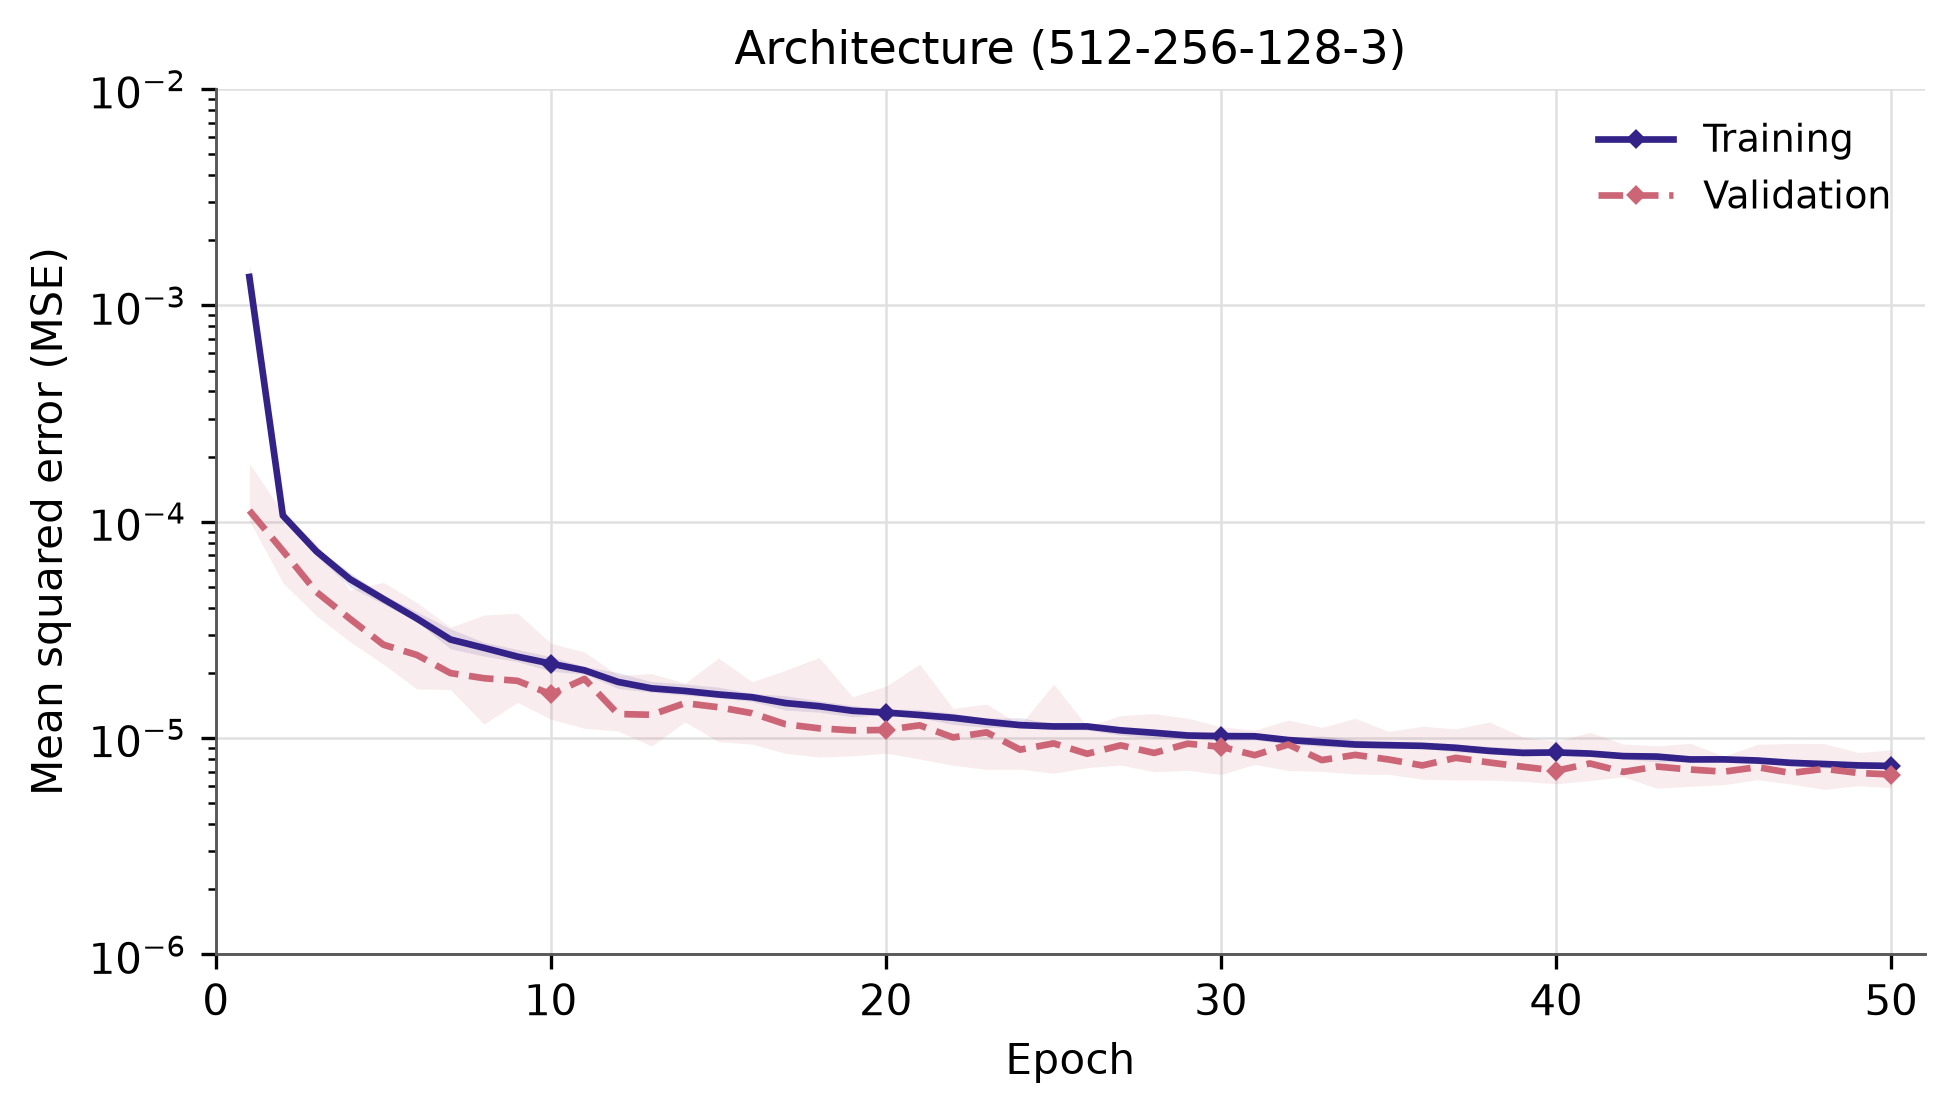

In [11]:
# Evaluate the three-hidden-layer network
train_architecture(ARCHITECTURES[0])
show_learning_curve(ARCHITECTURES[0], "training")

## Model Selection and Evaluation

### Validation Ranking

In [12]:
# Rank architectures by normalized validation error
training_variance = np.var(np.asarray(y_train), axis=0, ddof=0)
if np.any(training_variance <= 0):
    raise ValueError("Each target must have nonzero training-set variance")
validation_scores = []
for name, runs in validation_metrics.items():
    normalized_mse = (
        runs[[f"{target}_mse" for target in TARGETS]].to_numpy() / training_variance
    )
    validation_scores.append(
        {
            "Architecture": name,
            "Score": normalized_mse.mean(),
            **{target: normalized_mse[:, j].mean() for j, target in enumerate(TARGETS)},
            "Parameters": models[name].count_params(),
        }
    )

validation_ranking = (
    pd.DataFrame(validation_scores)
    .sort_values(["Score", "Parameters", "Architecture"])
    .reset_index(drop=True)
)
ranked_names = validation_ranking["Architecture"].tolist()
selected_architecture = ranked_names[0]
case_numbers = {name: i for i, name in enumerate(histories, start=1)}
selection_table = validation_ranking[["CL", "CD", "Cm", "Score", "Parameters"]].copy()
selection_table.index = model_index(ranked_names, case_numbers)
selection_table.columns = pd.MultiIndex.from_tuples(
    [("Normalized MSE", target) for target in TARGETS]
    + [("Normalized MSE", "Mean"), ("Model", "Parameters")]
)
print("Validation selection scores (lower is better)")
show_table(selection_table)
print("Validation MSE and R² (mean across seeded runs)")
validation_details = metric_table(
    ranked_names, validation_metrics, [("mse", "MSE"), ("r2", "R²")], case_numbers
)
validation_details[("R²", "Mean")] = validation_details["R²"].mean(axis=1)
show_table(validation_details)
print(f"Selected architecture: {architecture(selected_architecture)}")

Validation selection scores (lower is better)


Validation MSE and R² (mean across seeded runs)


Selected architecture: (512-256-128-3)


### Held-Out Test Results

In [13]:
# Report test scores for the validation-selected architecture
y_final = test_predictions[selected_architecture]
print(
    f"Test performance for {architecture(selected_architecture)} (mean across seeded runs)"
)
selected_test_results = metric_table(
    [selected_architecture], metrics, [("mse", "MSE"), ("r2", "R²")], case_numbers
)
show_table(selected_test_results)

Test performance for (512-256-128-3) (mean across seeded runs)


### Target vs Predicted Coefficients

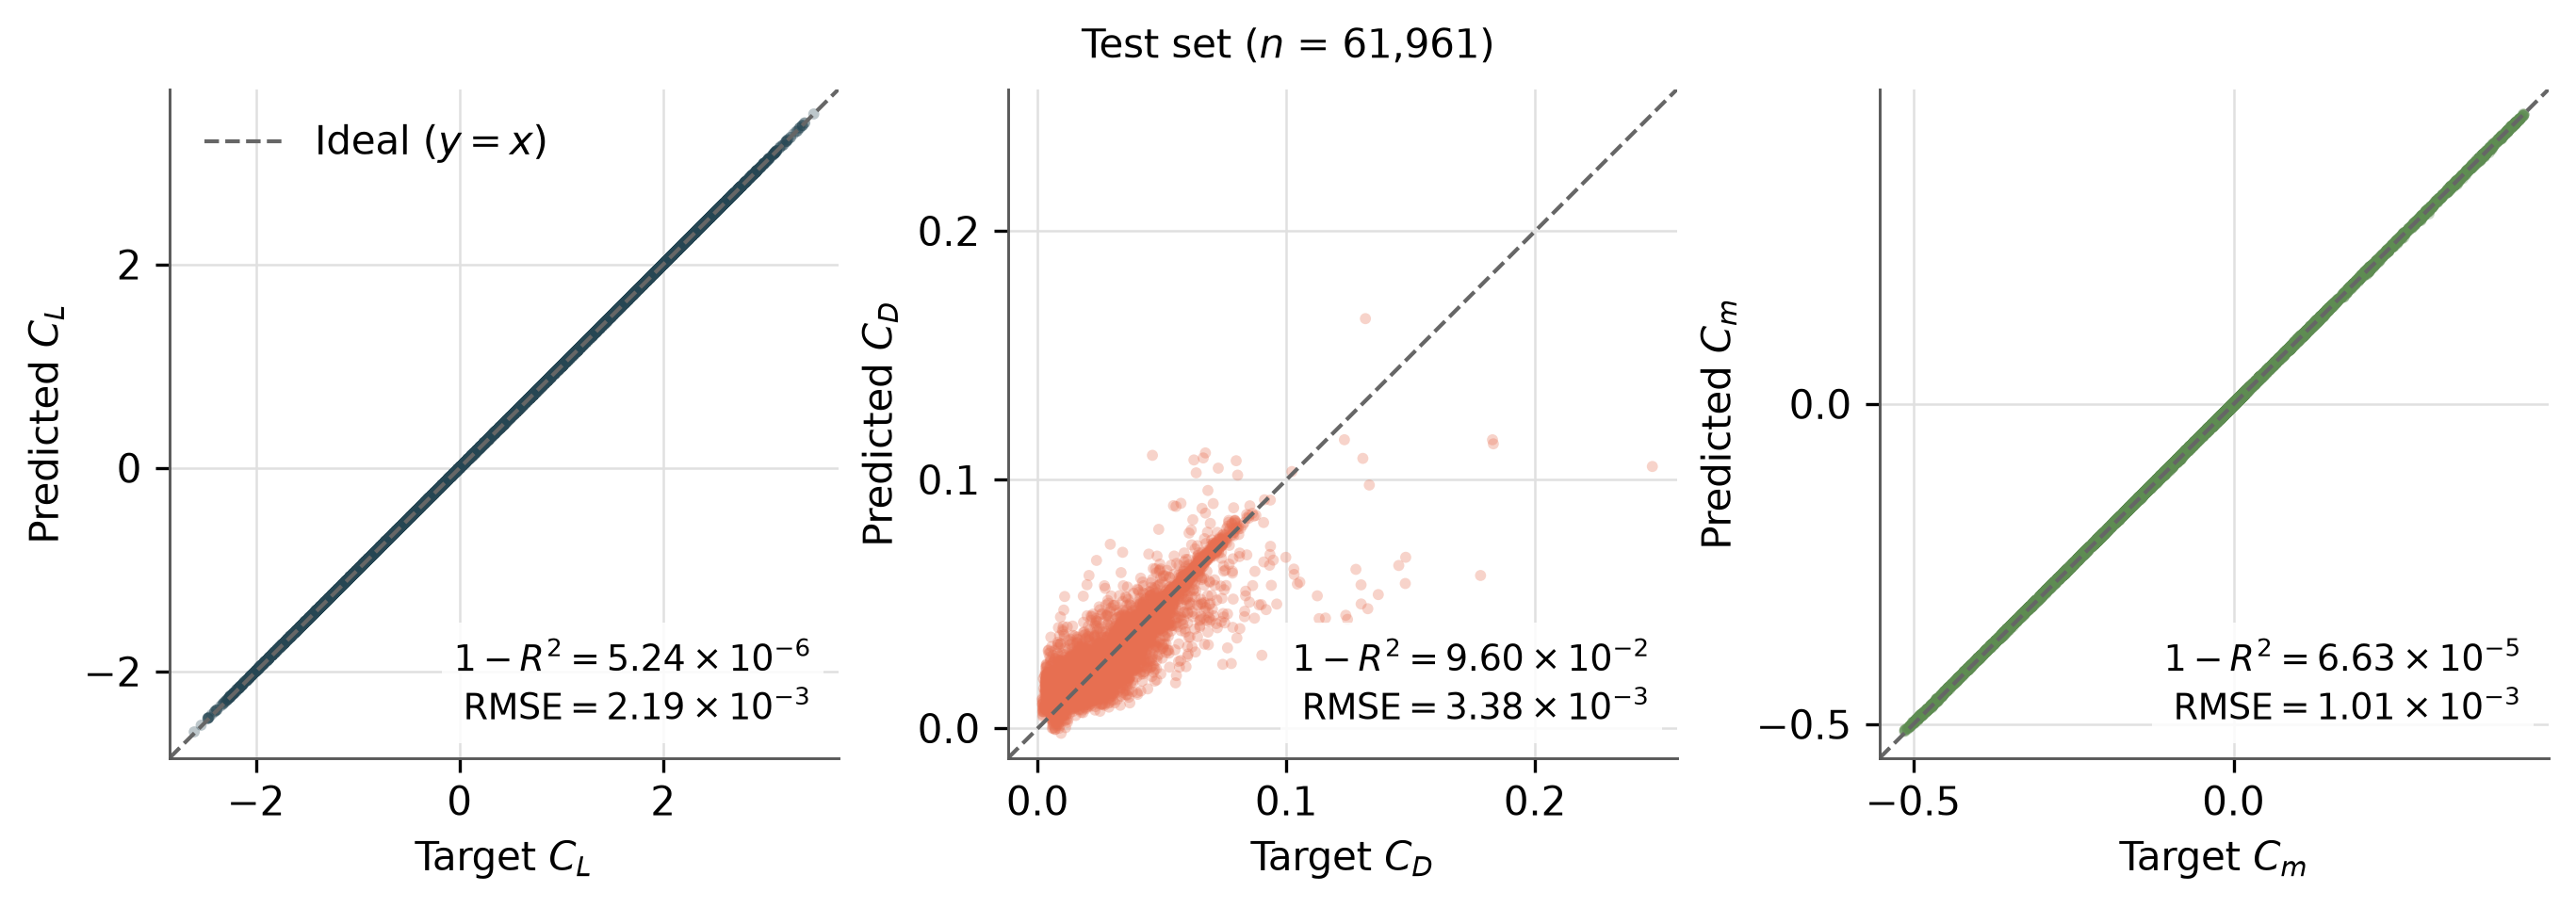

In [14]:
# Compare actual and predicted coefficients for the fixed-seed run
def scientific_notation(value):
    if value == 0:
        return "0"
    mantissa, exponent = f"{value:.2e}".split("e")
    return rf"{mantissa} \times 10^{{{int(exponent)}}}"


actual = np.asarray(y_test)
parity_rmse = np.sqrt(mean_squared_error(actual, y_final, multioutput="raw_values"))
parity_r2 = r2_score(actual, y_final, multioutput="raw_values")
fig, axes = plt.subplots(1, 3, figsize=(9, 3.1))
for j, (ax, target, color) in enumerate(
    zip(axes, [r"$C_L$", r"$C_D$", r"$C_m$"], ["#264653", "#E76F51", "#5E8C52"])
):
    low = min(actual[:, j].min(), y_final[:, j].min())
    high = max(actual[:, j].max(), y_final[:, j].max())
    pad = max((high - low) * 0.04, 1e-6)
    locator = MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10])
    ticks = locator.tick_values(low - pad, high + pad)
    limits = (low - pad, high + pad)
    ticks = ticks[(ticks >= limits[0]) & (ticks <= limits[1])]
    ax.plot(
        limits,
        limits,
        color="0.4",
        linestyle="--",
        linewidth=1,
        label=r"Ideal ($y = x$)",
    )
    ax.scatter(
        actual[:, j],
        y_final[:, j],
        s=8,
        marker="o",
        color=color,
        alpha=0.3,
        edgecolors="none",
        linewidths=0,
    )
    ax.set(
        xlabel=f"Target {target}",
        ylabel=f"Predicted {target}",
        xlim=limits,
        ylim=limits,
    )
    ax.text(
        0.96,
        0.04,
        rf"$1 - R^2 = {scientific_notation(1 - parity_r2[j])}$"
        "\n"
        rf"$\mathrm{{RMSE}} = {scientific_notation(parity_rmse[j])}$",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 3},
    )
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.ticklabel_format(axis="both", style="sci", scilimits=(-3, 4))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(axis="both", which="major", color="0.88", linewidth=0.6)
axes[0].legend(fontsize=10)
fig.align_ylabels()
fig.text(
    0.5, 0.98, f"Test set ($n$ = {len(actual):,})", ha="center", va="top", fontsize=10
)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.96))
finish_figure(
    fig,
    "held-out-parity",
    caption=f"Test set (n = {len(actual):,}). Target and predicted coefficients for architecture "
    f"{architecture(selected_architecture)}. Seed 42 is fixed in advance and is not "
    "selected by validation or test performance. Panel metrics (1 − R² and RMSE) are computed "
    "from the plotted test predictions in the original coefficient scale, not averaged "
    "across training runs. The dashed line shows ideal agreement.",
)

## Geometric Design Space

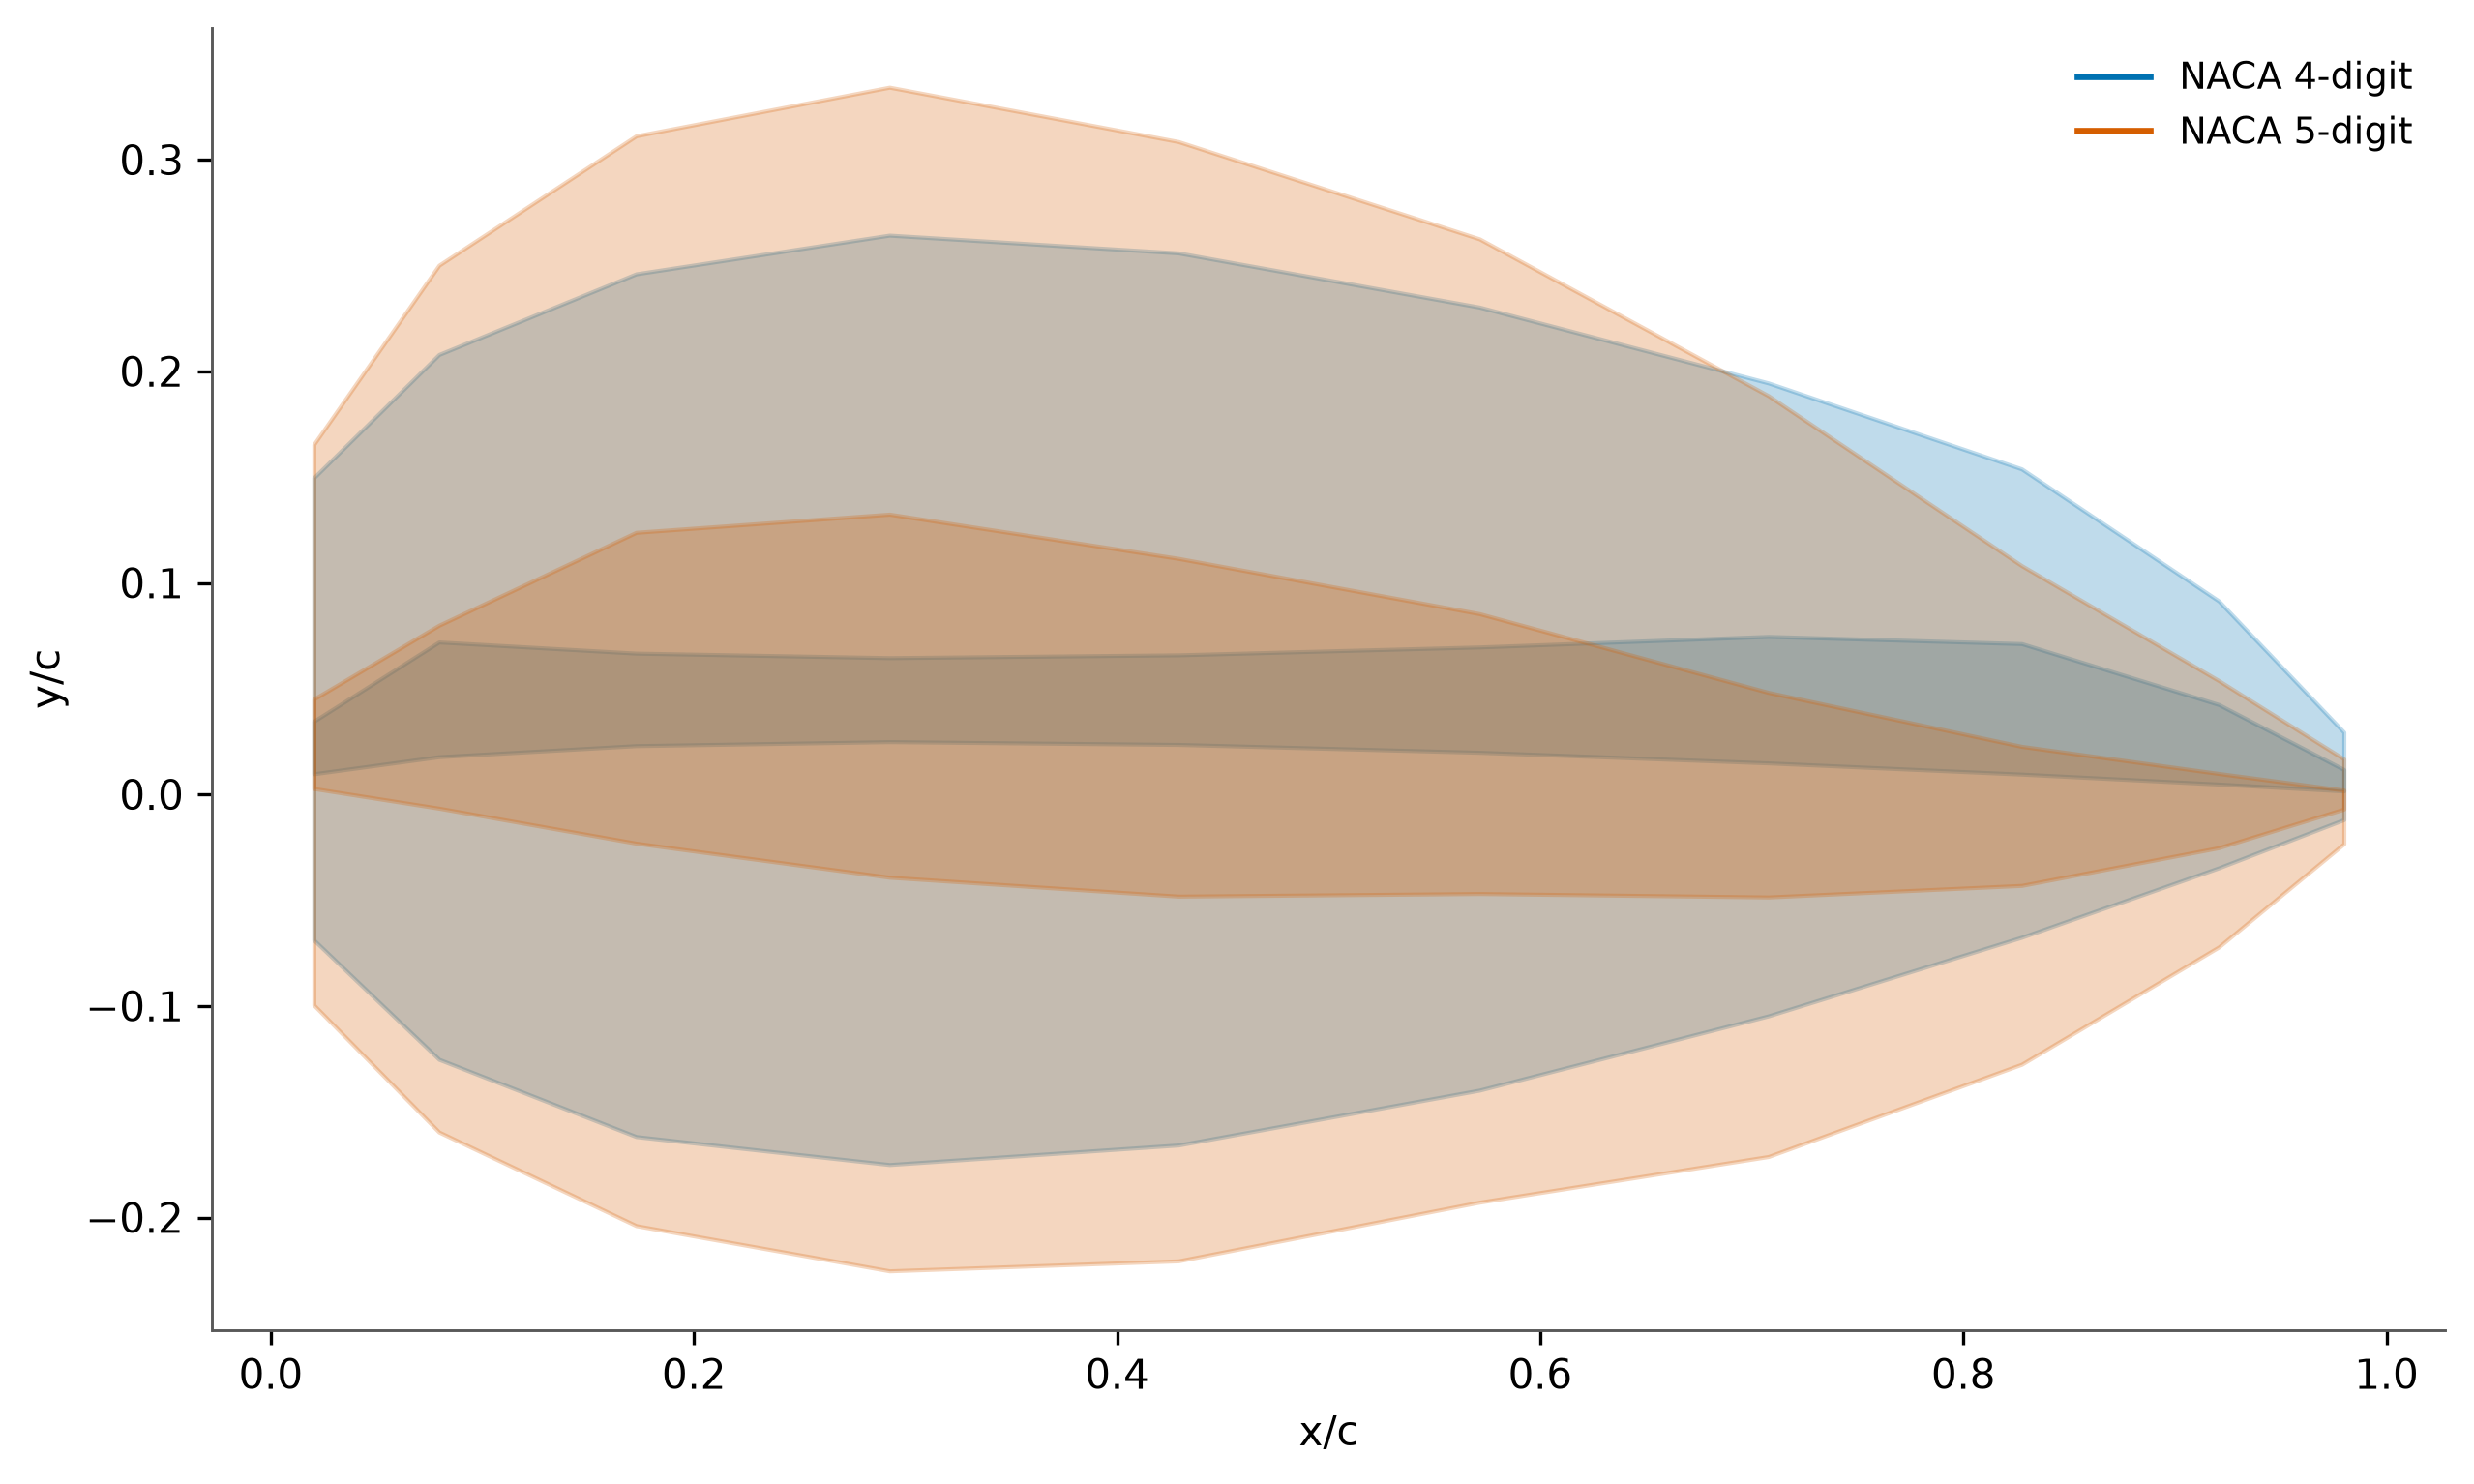

In [15]:
# Compare geometry envelopes at the sampled surface coordinates
fig, ax = plt.subplots(figsize=(10, 5))
for frame, label, color in [
    (df4, "NACA 4-digit", BLUE),
    (df5, "NACA 5-digit", ORANGE),
]:
    upper = sorted([c for c in frame if c.startswith("yU")], key=lambda c: int(c[2:]))
    lower = sorted([c for c in frame if c.startswith("yL")], key=lambda c: int(c[2:]))
    geometry = frame[upper + lower].drop_duplicates()
    x = 0.5 * (1 - np.cos(np.linspace(0, np.pi, len(upper) + 2)[1:-1]))
    for columns in [upper, lower]:
        values = geometry[columns].to_numpy()
        ax.fill_between(
            x, values.min(axis=0), values.max(axis=0), color=color, alpha=0.25
        )
    ax.plot([], [], color=color, label=label)
ax.set(xlabel="x/c", ylabel="y/c")
ax.set_aspect("equal", adjustable="box")
ax.legend()
finish_figure(
    fig,
    "geometry-envelope",
    caption="Geometry envelopes of the NACA 4-digit and 5-digit airfoils at the sampled surface coordinates.",
)

## Independent Reference-Airfoil Evaluation

In [16]:
# Evaluate independent reference airfoils when data is available
reference_path = ROOT / "results" / "reference_airfoils.csv"
if not reference_path.is_file():
    print(f"Figures 5–7 require independent reference data: {reference_path}")
else:
    reference = pd.read_csv(reference_path, dtype={"airfoil": str})
    required = ["airfoil", *X.columns, "CL", "CD", "Cm"]
    missing = set(required) - set(reference.columns)
    if missing:
        raise ValueError(f"Missing reference columns: {sorted(missing)}")
    names = ["0045", "2412", "6408", "136138"]
    if set(reference["airfoil"]) != set(names):
        raise ValueError(f"Expected precisely these airfoils: {names}")
    if not (
        np.isclose(reference["M"], 0.25).all()
        and np.isclose(reference["Re"], 250000).all()
    ):
        raise ValueError("Reference conditions must be M=0.25 and Re=250000")
    if not np.isfinite(
        reference[list(X.columns) + ["CL", "CD", "Cm"]].to_numpy()
    ).all():
        raise ValueError("Reference data must contain finite numeric values")
    predictions = models[selected_architecture].predict(
        X_scaler.transform(reference[X.columns]), verbose=0
    )
    for target, figure_number in [("CL", 5), ("Cm", 6), ("CD", 7)]:
        fig, ax = plt.subplots(figsize=(9, 5))
        for name in names:
            indices = np.flatnonzero(reference["airfoil"].eq(name).to_numpy())
            indices = indices[np.argsort(reference.iloc[indices]["alpha"].to_numpy())]
            rows = reference.iloc[indices]
            (line,) = ax.plot(rows["alpha"], rows[target], label=f"NACA {name} target")
            ax.plot(
                rows["alpha"],
                predictions[indices, ["CL", "CD", "Cm"].index(target)],
                "--",
                color=line.get_color(),
                label=f"NACA {name} predicted",
            )
        ax.set(
            xlabel="Angle of attack α (deg)",
            ylabel=target,
        )
        ax.legend(ncol=2)
        finish_figure(
            fig,
            f"reference-{target.lower()}",
            caption=f"Target and predicted {target} versus angle of attack at M = 0.25 and Re = 250,000.",
        )

Figures 5–7 require independent reference data: /home/nevilcp/Desktop/projects/aerodynamic-coefficient-prediction-ann/results/reference_airfoils.csv


## Architecture Performance Comparison

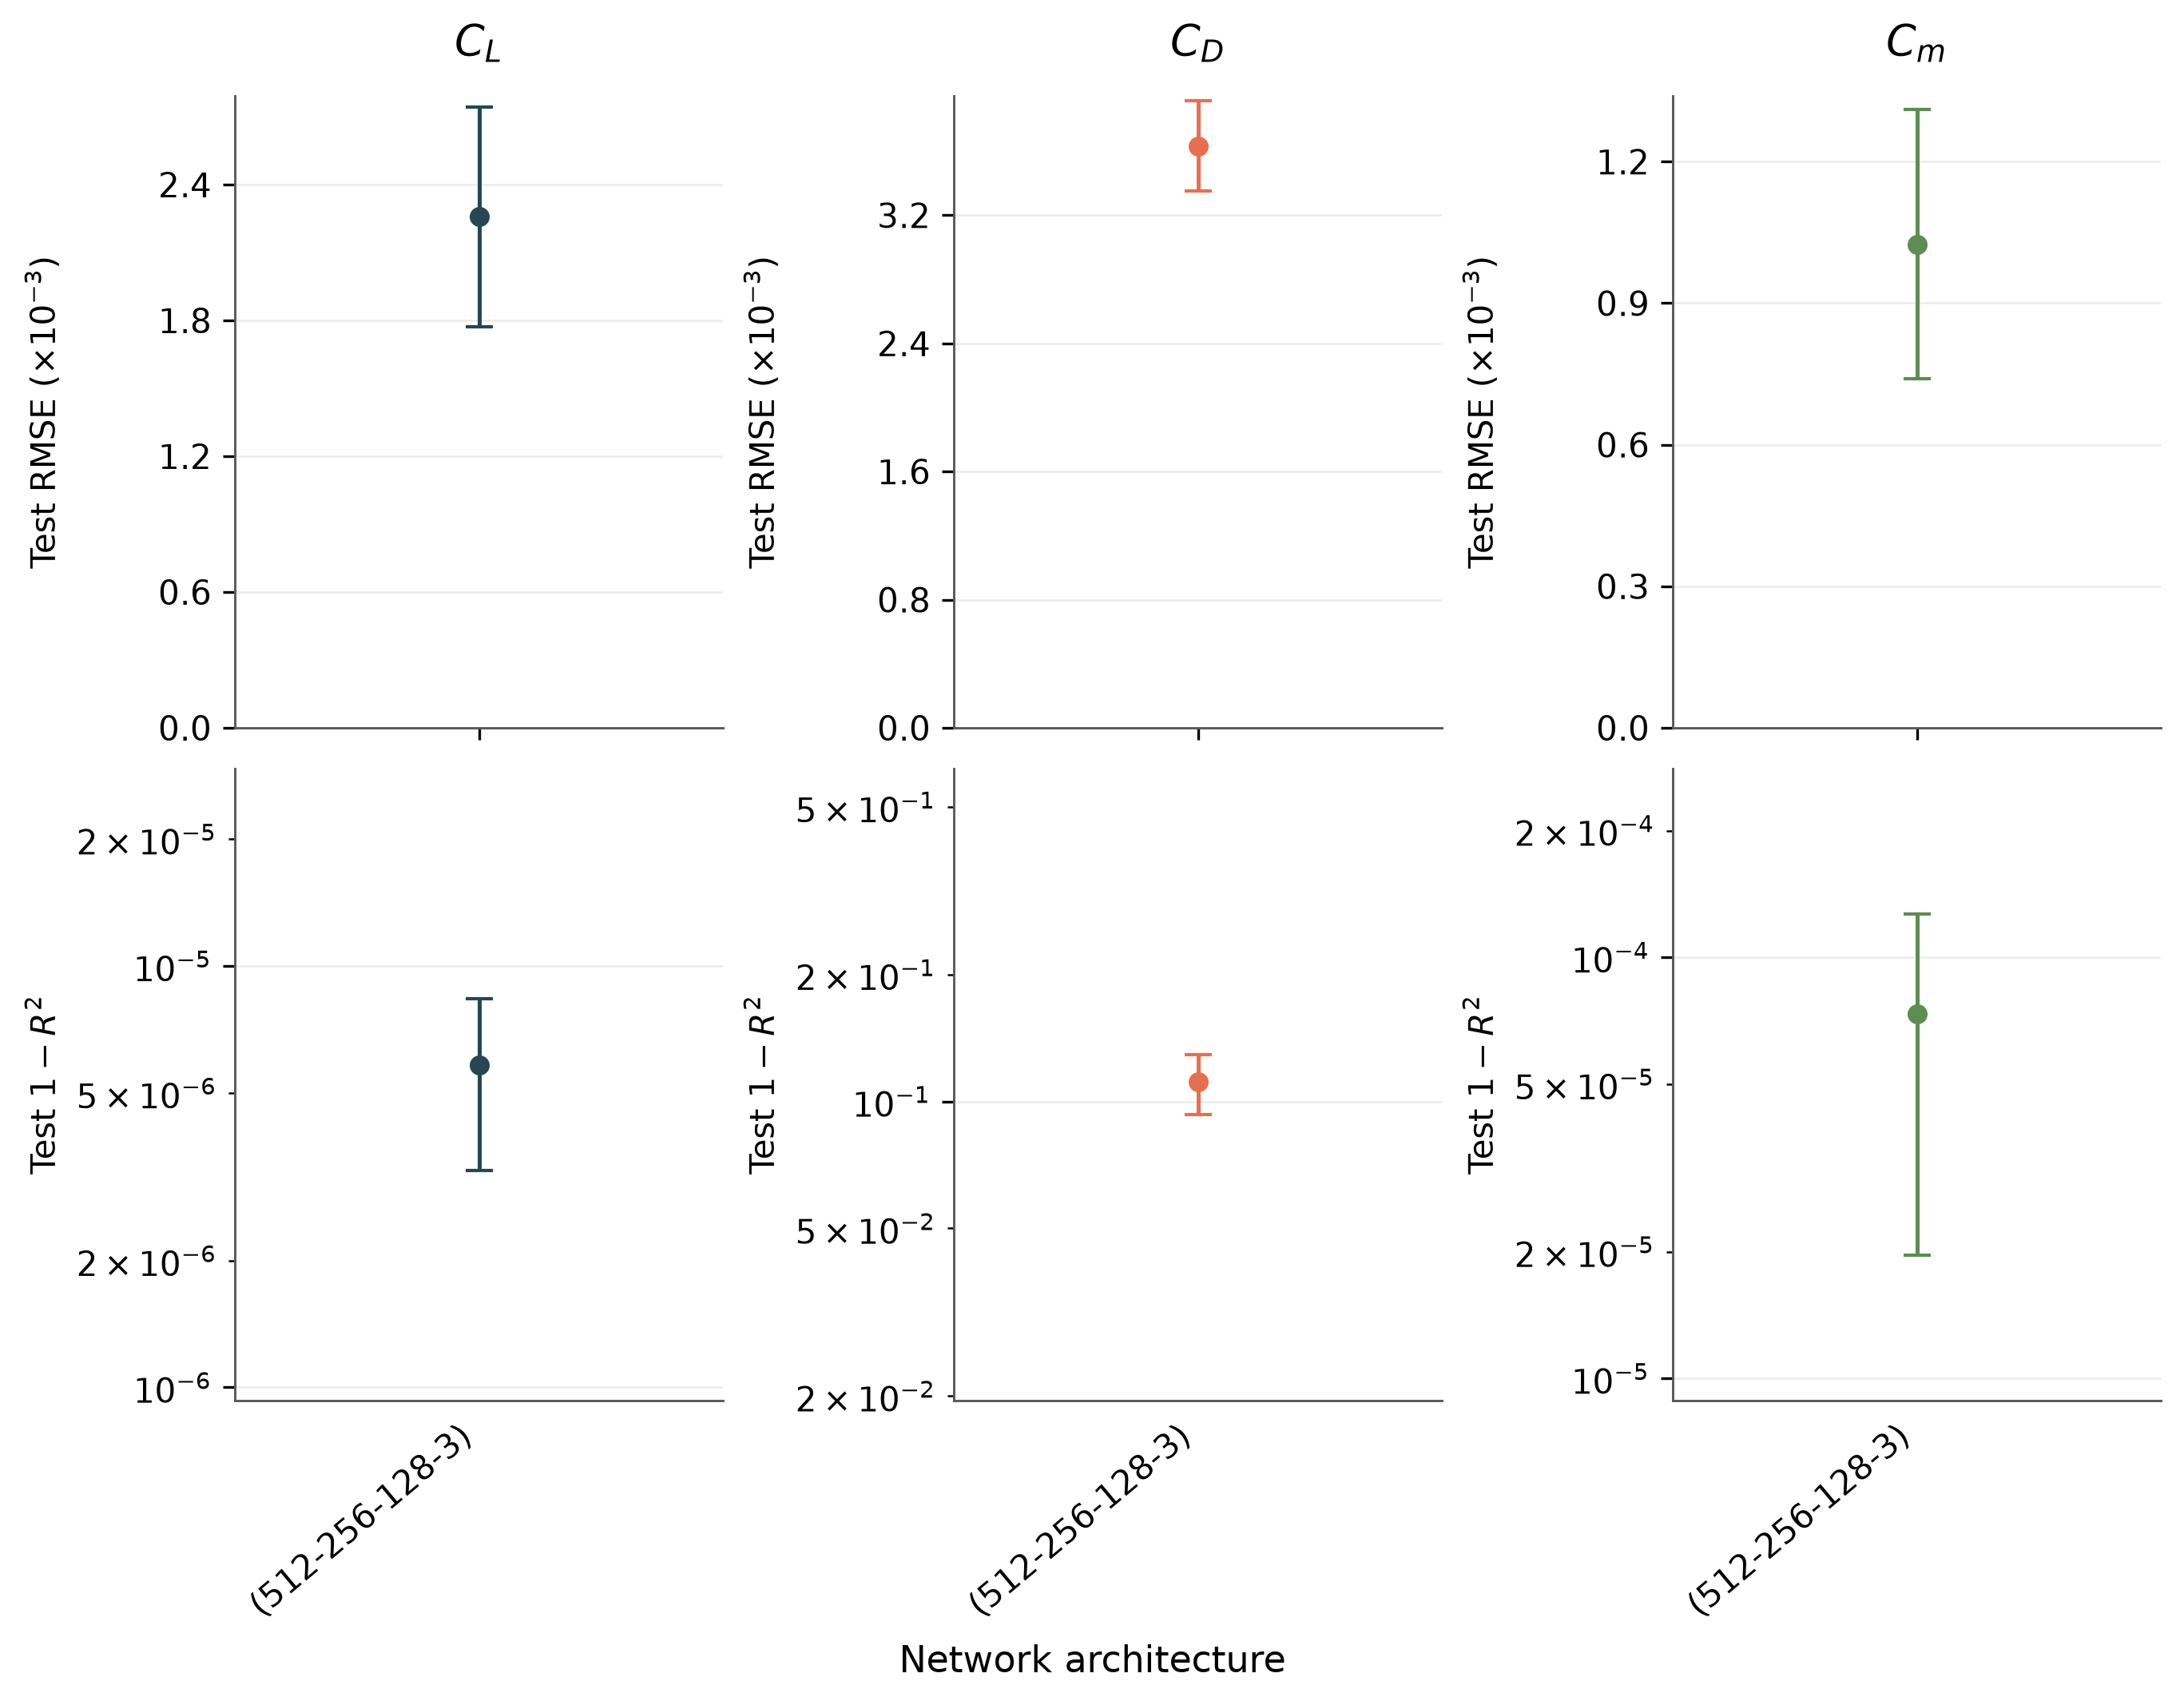

In [17]:
# Compare test RMSE and R² across network architectures
from matplotlib.ticker import FormatStrFormatter, LogFormatterSciNotation, LogLocator

# Separate depth and width experiments; the shared baseline appears in both.
if "DEPTH_ARCHITECTURES" in globals():
    plot_groups = [
        ("depth", globals()["DEPTH_ARCHITECTURES"]),
        ("width", globals()["WIDTH_ARCHITECTURES"]),
    ]
else:
    plot_groups = [(None, ARCHITECTURES)]
# Update the learning curves to use shared axis limits
loss_limits = learning_curve_limits()
for group, names in plot_groups:
    for name in names:
        show_learning_curve(name, group or "training", loss_limits)
for group, names in plot_groups:
    fig, axes = plt.subplots(2, 3, figsize=(9, 7), sharex=True)
    x = np.arange(len(names))
    for j, (target, symbol, color) in enumerate(
        zip(TARGETS, [r"$C_L$", r"$C_D$", r"$C_m$"], ["#264653", "#E76F51", "#5E8C52"])
    ):
        for row, suffix, ylabel in [
            (0, "rmse", "Test RMSE"),
            (1, "r2", r"Test $1 - R^2$"),
        ]:
            ax = axes[row, j]
            values = [metrics[name][f"{target}_{suffix}"] for name in names]
            if row == 1:
                values = [1 - v for v in values]
            means = np.array([v.mean() for v in values])
            deviations = np.array([v.std(ddof=1) if len(v) > 1 else 0 for v in values])
            if row == 0:
                means = means * 1e3
                deviations = deviations * 1e3
                ylabel = r"Test RMSE ($\times 10^{-3}$)"
            ax.errorbar(
                x,
                means,
                yerr=deviations,
                fmt="o",
                color=color,
                markersize=5,
                capsize=4,
                linewidth=1.2,
            )
            ax.set_ylabel(ylabel)
            ax.set_xlim(-0.5, len(names) - 0.5)
            ax.grid(axis="y", color="0.92", linewidth=0.6)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            if row == 0:
                ax.set_title(symbol, fontsize=13, pad=12)
                ax.set_ylim(bottom=0)
                ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
            else:
                if np.any(means <= 0):
                    raise ValueError(
                        "Logarithmic 1 − R² plots require positive mean errors"
                    )
                # Use the same limits for depth and width; retain all mean ± SD bars.
                error_runs = [
                    1 - metrics[name][f"{target}_r2"] for name in ARCHITECTURES
                ]
                error_means = np.array([v.mean() for v in error_runs])
                error_sd = np.array(
                    [v.std(ddof=1) if len(v) > 1 else 0 for v in error_runs]
                )
                positive_errors = np.concatenate(
                    [v[v > 0].to_numpy() for v in error_runs]
                )
                lower = np.min(error_means - error_sd)
                if lower <= 0:
                    lower = positive_errors.min()
                upper = np.max(error_means + error_sd)
                log_low, log_high = np.log10([lower, upper])
                center = (log_low + log_high) / 2
                half_span = max(0.75, (log_high - log_low) / 2 + 0.08)
                ax.set_yscale("log")
                ax.set_ylim(10 ** (center - half_span), 10 ** (center + half_span))
                ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1,), numticks=10))
                ax.yaxis.set_minor_locator(
                    LogLocator(base=10, subs=(2, 5), numticks=20)
                )
                for which in ["major", "minor"]:
                    formatter = LogFormatterSciNotation(
                        base=10, labelOnlyBase=False, minor_thresholds=(np.inf, np.inf)
                    )
                    if which == "major":
                        ax.yaxis.set_major_formatter(formatter)
                    else:
                        ax.yaxis.set_minor_formatter(formatter)
                ax.tick_params(axis="y", which="minor", labelsize=10)
                ax.set_xticks(
                    x,
                    [architecture(name) for name in names],
                    rotation=40,
                    ha="right",
                    fontsize=10,
                )
                ax.tick_params(axis="x", length=0, pad=6)
    fig.supxlabel("Network architecture", fontsize=11)
    fig.align_ylabels()
    comparison = (
        f"{group.capitalize()} comparison" if group else "Architecture comparison"
    )
    finish_figure(
        fig,
        f"architecture-metrics-{group}" if group else "architecture-metrics",
        caption=f"{comparison}. Test RMSE and 1 − R²: mean ± SD across {N_RUNS} independent training runs (random seeds). "
        "RMSE values are shown in units of 10⁻³. The 1 − R² axis is logarithmic; lower values indicate better predictions.",
    )